**copied from /admin-where-is-M1/w1-extract-cm229-topo.ipynb**

In [ ]:
import sys; sys.path.insert(0, '../..')
from paths import ROOT, DATA, STEPS, PREPARES, FIGURES, OUTPUT, CODE


In [3]:
import h5py
import pickle
import scipy
import numpy as np
import seaborn as sns
# sns.set()
sns.set_style("whitegrid", {'axes.grid' : False})
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import pandas as pd
from os.path import join as pjoin
import scipy.io as sio
from scipy import stats
import scipy.signal as sp
from scipy import signal
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

from statannot import add_stat_annotation
from skimage import io
from skimage.feature import hog
from joblib import Parallel, delayed
import cv2
import glob
import time
from skimage.registration import phase_cross_correlation
from scipy.ndimage import fourier_shift
from joblib import Parallel, delayed
from skimage.feature import hog
import sys
sys.path.insert(1, str(CODE / 'make_0_prepare' / 'common-functions'))
from harness import *
from f2_utils import *
import matplotlib.patches as patches

from IPython.display import display, clear_output, HTML, Image
from matplotlib import animation, rc

from skimage.measure import regionprops

from matplotlib import cm as mpl_cm
from matplotlib import (colors,
                        lines,
                        transforms,
                        )
from matplotlib import patches

import time_in_each_roi 
from skimage import measure

In [10]:
prefix = '/mnt/staging/' # or 
step_0_root = str(STEPS / "step_0/RS_3mice") + "/"
step_1_root = str(STEPS / "step_1") + "/"
mouse='cm126'

fetch_path_S1 = str(PREPARES / "index-S1") + "/"
fetch_path_M2 = str(PREPARES / "index-M2") + "/"
fetch_path_M1 = str(FIGURES / "figure5") + "/"
fetch_path_extra = str(PREPARES / "index-extra") + "/"
figure_config_root = str(PREPARES / "config") + "/"



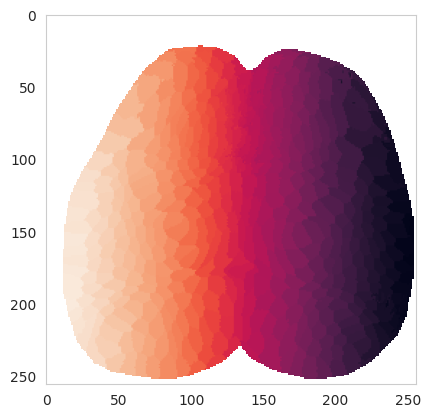

In [38]:
with h5py.File(step_0_root+'idx_sorted_500_{}.mat'.format(mouse),'r') as f_idx:

    IDX_sorted = np.array(f_idx['IDX_sorted']).T
    IDX_sorted = IDX_sorted.astype(float)
    IDX_sorted[IDX_sorted==0]='nan'
    num_regions = int(np.nanmax(IDX_sorted.reshape((-1,1))))
    props = regionprops(IDX_sorted.astype(int))
    node_coords = [props[i].centroid for i in range(len(props))]
    node_coords = np.asarray(node_coords, dtype=np.float32)
    
    mask = IDX_sorted >0
    mask = mask.astype(float)
    mask[mask==0]='nan'
plt.imshow(IDX_sorted)

In [58]:
with h5py.File(figure_config_root+'mask_midline_'+mouse+'.mat','r') as f_midline:
    mask_midline = np.array(f_midline['mask_midline']).T

In [76]:
list_contours = []
for i_index in range(500):
    target_region = IDX_sorted == i_index +1
    contours = measure.find_contours(target_region, level=0.5)
    list_contours.append(contours)

In [6]:
M_raw={}
t1 = 340
with h5py.File(step_1_root+'{}/{}/{}_stim_1.mat'.format(mouse,'1','runB'),'r') as f_H: 
    for key in ['green','lime','red']:
        C = np.array(f_H['C'][key])
        S = np.array(f_H['S'][key])[t1:t1+1,:]
        CS = np.dot(S,C).transpose()

        temp = CS
        temp = temp.reshape((256,256,-1)).transpose((1,0,2))     

        # temp_norm = temp-np.mean(temp[:,:,bsl],axis=-1)[:,:,np.newaxis]
        M_raw[key] = temp


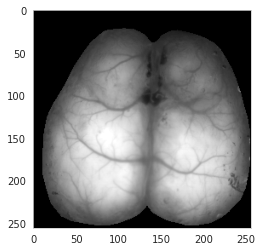

In [7]:
masked_brain = np.multiply(np.squeeze(M_raw['lime']),mask)
masked_brain=np.nan_to_num(masked_brain,0)
plt.imshow(masked_brain,cmap='gray',vmin=0,vmax=4300)

In [61]:

palatte_dict = load_pickle(figure_config_root+'palatte_dict')
palatte_dict['mouth_M2']='#bf8fc9'
palatte_dict['RFP_M2']='#6dae96'
palatte_dict['RFP_M1']='#4b0082'
palatte_dict['LatM']=palatte_dict['ALM']



In [9]:
def save_pickle(model,pkl_filename):
    with open(pkl_filename, 'wb') as file:
        pickle.dump(model, file)

def load_pickle(pkl_filename):
    with open(pkl_filename, 'rb') as file:
        pickle_model = pickle.load(file)
    return pickle_model


**load data**

In [72]:
M2_ind = load_pickle(fetch_path_M2+'brightest_frontline_ind-'+mouse)
sensory_ind = load_pickle(fetch_path_S1+'inferred_brightest_ind_'+mouse)
all_ind = sensory_ind.copy()
extra_ind = load_pickle(fetch_path_extra+'extra_ind_'+mouse)
extra_extra_ind = load_pickle(fetch_path_extra+'extra_extra_ind_'+mouse)
all_ind.update(extra_ind)
sensory_ind['RM']=extra_extra_ind['right_mouth_sensory']
sensory_ind['LM']=sensory_ind['mouth']
mega_dict = load_pickle(fetch_path_M1+'mega_dict_coherence_'+mouse)
M1_ind_from_coherence = mega_dict['mega_M1_ind_from_coherence']

In [78]:
extra_extra_ind

{'right_mouth_sensory': 486,
 'right_mouth_motor': 362,
 'right_nose_sensory': 499,
 'right_nose_motor': 335,
 'left_nose_sensory': 1,
 'left_nose_motor': 170,
 'left_visual': 77,
 'left_visual_motor': 231,
 'right_visual': 399,
 'right_visual_motor': 280}

In [83]:
choice_body_part_dict = {0:'RHP',1:'RFP',2:'RN',3:'RV',
                         4:'RM_M2',5:'RFP_M2',6:'LatM'}
choice_dict = {0:344,1:415,2:489,3:399,4:362,5:328,6:432}

In [84]:
if mouse =='cm126':
    bregma=np.array([138,114])
if mouse =='cm128':    
    bregma=np.array([135,110])

pixels_per_mm = 29
x_axis = np.divide(np.linspace(-bregma[0],256-bregma[0]-1,256),pixels_per_mm)
y_axis = np.divide(np.linspace(256-bregma[1]-1,-bregma[1],256),pixels_per_mm)

extent = [x_axis[0],x_axis[-1],y_axis[-1],y_axis[0]]

In [85]:
def contour_to_roi(image,contour):
    import scipy.ndimage as ndimage  
    r = mask
    # Create an empty image to store the masked array
    r_mask = np.zeros_like(r, dtype='bool')
    # r_mask[:]=np.nan

    # Create a contour image by using the contour coordinates rounded to their nearest integer value
    r_mask[np.round(contour[:, 0]).astype('int'), np.round(contour[:, 1]).astype('int')] = 1

    # Fill in the hole created by the contour boundary
    r_mask = ndimage.binary_fill_holes(r_mask)

    # Invert the mask since you want pixels outside of the region
    # r_mask = ~r_mask
    
    r_mask = r_mask.astype('float')
    r_mask[r_mask == 0] = np.nan

    return r_mask

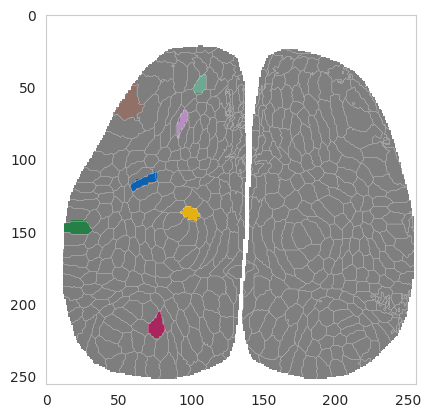

In [86]:
from skimage import measure
plt.imshow(np.multiply(mask_midline,IDX_sorted),vmin=-30000,vmax=30000,cmap='gray_r')
for i_index in range(500):
    for contour in list_contours[i_index]:
        plt.plot(contour[:, 1], contour[:, 0], linewidth=0.1, color='white')

        
for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    for contour in list_contours[ind]:
        
        ROI_2_plot = contour_to_roi(np.ones((256,256)),contour)
        color_here = palatte_dict[bdp]
        c_black= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 1)
        c_black1= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 0.95)
        c_white= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 0.9)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        plt.imshow(ROI_2_plot,cmap=cmap_rb)


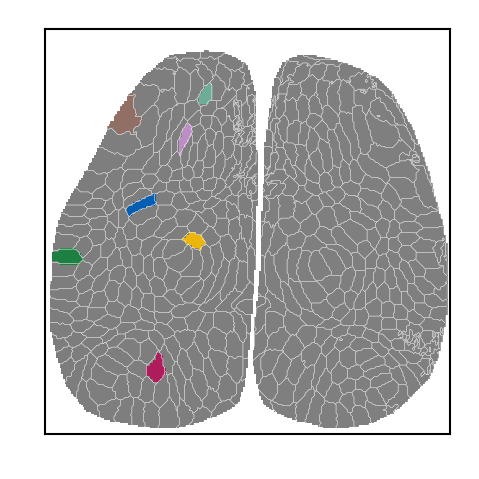

In [121]:
from matplotlib.gridspec import GridSpec
from skimage import measure
from matplotlib import ticker
import matplotlib
plt.style.use('default')

gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)

y_offset = 20;x_offset=20;
x_width=6;

x_start = x_offset
x_stop = x_start+x_width
ax0 = fig.add_subplot(gs[y_offset:y_offset+6,x_start:x_stop])


from skimage import measure
ax0.imshow(np.multiply(mask_midline,IDX_sorted),vmin=-30000,vmax=30000,cmap='gray_r')
for i_index in range(500):
    for contour in list_contours[i_index]:
        ax0.plot(contour[:, 1], contour[:, 0], linewidth=0.07, color='white')

        
for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
    ind = choice_dict[i_bdp]
    bdp = choice_body_part_dict[bdp_ind]
    for contour in list_contours[ind]:
        ROI_2_plot = contour_to_roi(np.ones((256,256)),contour)
        color_here = palatte_dict[bdp]
        c_black= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 1)
        c_black1= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 0.99)
        c_white= matplotlib.colors.colorConverter.to_rgba(color_here,alpha = 0.98)
        cmap_rb = matplotlib.colors.LinearSegmentedColormap.from_list('rb_cmap',[c_white,c_black1,c_black],5120)
        ax0.imshow(ROI_2_plot,cmap=cmap_rb)
        
        
        


# ax0.imshow(masked_brain,cmap='gray',vmin=0,vmax=4500,extent=extent)
# for i_bdp,bdp_ind in enumerate(choice_body_part_dict):
#     y_value = 100+i_bdp*30
    
#     ind = choice_dict[i_bdp]
#     bdp = choice_body_part_dict[bdp_ind]
#     ax0.scatter(x_axis[int(node_coords[ind,1])],y_axis[int(node_coords[ind,0])],s=20,color=palatte_dict[bdp],label=bdp)
#     ax0.text(x_axis[int(node_coords[ind,1])],y_axis[int(node_coords[ind,0]-10)],i_bdp+1,
#          color=palatte_dict[bdp])
    
#     # ax0.text(-65,y_value,
#     #          bdp,color=palatte_dict[bdp])
    
    
# ax0.scatter(0,0,s=30,marker='+',color='white',alpha=0.8) #bregma location
# ax0.legend(loc='center left',fontsize=7, bbox_to_anchor=(1, 0.5))
# ax0.set_title('ROI location')
# ax0.set_xlabel('L-R (mm)')
# ax0.set_ylabel('P-A (mm)')
ax0.set_xlim([8,256]);
ax0.set_ylim([256,8]);

        
for i_part,part in enumerate(['top','bottom','left','right']):
    ax0.spines[part].set_linewidth(0.5)
        
ax0.set_xticks([]);ax0.set_yticks([]);

plt.savefig('figS7-ROIs-{}.svg'.format(mouse),format='svg',dpi=300)



In [19]:
behavior_colors = ['#E64B35', '#4DBBD5', '#00A087', '#3C5488',
                  '#F39B7F', '#8491B4', '#91D1C2FF','#7E6148','#B09C85', '#DC0000'
                   ]

In [20]:
col_list = ["grey"] +  ["dark magenta"] + ["emerald green"] + ["golden rod"] + ["tomato"] + ["marine blue"] +["medium blue"]
col_list_palette = sns.xkcd_palette(col_list)

# make single-trial figure first

In [21]:
# load data
fetch_path = str(PREPARES / "modeling") + "/"
data_joint = load_pickle(fetch_path+mouse+'_data_joint.pickle')
all_sessions = list(np.unique(data_joint.index.get_level_values(0)))
print(len(all_sessions),all_sessions)

16 ['cm126_1_runB', 'cm126_1_runF', 'cm126_1_runG', 'cm126_1_runH', 'cm126_1_runI', 'cm126_1_runJ', 'cm126_2_runF', 'cm126_2_runG', 'cm126_2_runH', 'cm126_2_runI', 'cm126_2_runJ', 'cm126_3_runB', 'cm126_3_runC', 'cm126_3_runH', 'cm126_3_runI', 'cm126_3_runJ']


In [22]:
session = 'cm126_3_runB'
X = np.array(data_joint.loc[session,:].iloc[:,:500])
y = np.array(data_joint.loc[session,:].iloc[:,500:])

In [23]:
# load linear model
linear_model = load_pickle(fetch_path+'linear_model_'+mouse)
y_predict_linear_model = linear_model.predict(X)

In [24]:
# load CNN model
from prepare_CNN_model import prepare_model
from prepare_CNN_model import load_model
from prepare_CNN_model import load_prepare_data

In [25]:
length=40
model_weights_filename = fetch_path+'cnn_weights_'+mouse+ '_len_'+str(length)+'.hdf5'

timesteps=length;num_in_features=500;num_out_features = 4
cnn_model = prepare_model('mean_absolute_error','mean_absolute_error',
                                        timesteps,
                                       num_in_features,
                                       num_out_features)
cnn_model.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 40, 500)]         0         
                                                                 
 conv1d (Conv1D)             (None, 40, 1024)          10241024  
                                                                 
 bidirectional (Bidirectiona  (None, 40, 200)          900000    
 l)                                                              
                                                                 
 dense (Dense)               (None, 40, 128)           25728     
                                                                 
 dense_1 (Dense)             (None, 40, 64)            8256      
                                                                 
 dense_2 (Dense)             (None, 40, 4)             260       
                                                             

In [26]:
cnn_model = load_model(cnn_model, model_weights_filename) # load model; it has been trained

In [27]:
def load_prepare_data(X_continued, y_continued,length=40,stride_length=5,num_regions=500):


    # slice the time series

    
    # split training, testing set
    X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.6,shuffle=True,random_state=7)
    print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)
    dataDict ={'X_train':X_train,
          'X_test':X_test,
          'y_train':Y_train,
          'y_test':Y_test}

    return dataDict

In [28]:
from TimeseriesGenerator import TimeseriesGenerator
data_gen = TimeseriesGenerator(X,y,
                               stride = 40,sampling_rate=1,
                               length=40,batch_size=1000000)
X_CNN , y_CNN = data_gen[0]

In [29]:
X_CNN.shape

(274, 40, 500)

In [30]:
Y_hat = cnn_model.predict(X_CNN)
Y_hat_concat = Y_hat.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))
Y_concat = y_CNN.reshape((Y_hat.shape[0]*Y_hat.shape[1],Y_hat.shape[-1]))


9/9 [==============================] - 2s 48ms/step


In [31]:
from sklearn.metrics import mean_squared_error,r2_score

In [32]:
t_range = np.r_[range(1280,2000),range(3000,5000),range(7000,8000),range(9000,10950)]
t_ax = np.divide(range(len(t_range)),20)

In [33]:

palette_body=['#e97877','#85A2B2','#7ba379','#f4c784']


In [113]:
import random
available_numbers = [num for num in range(250, 500) if num not in choice_dict.values()]
random.seed(7)
chosen_numbers = random.sample(available_numbers, 6)


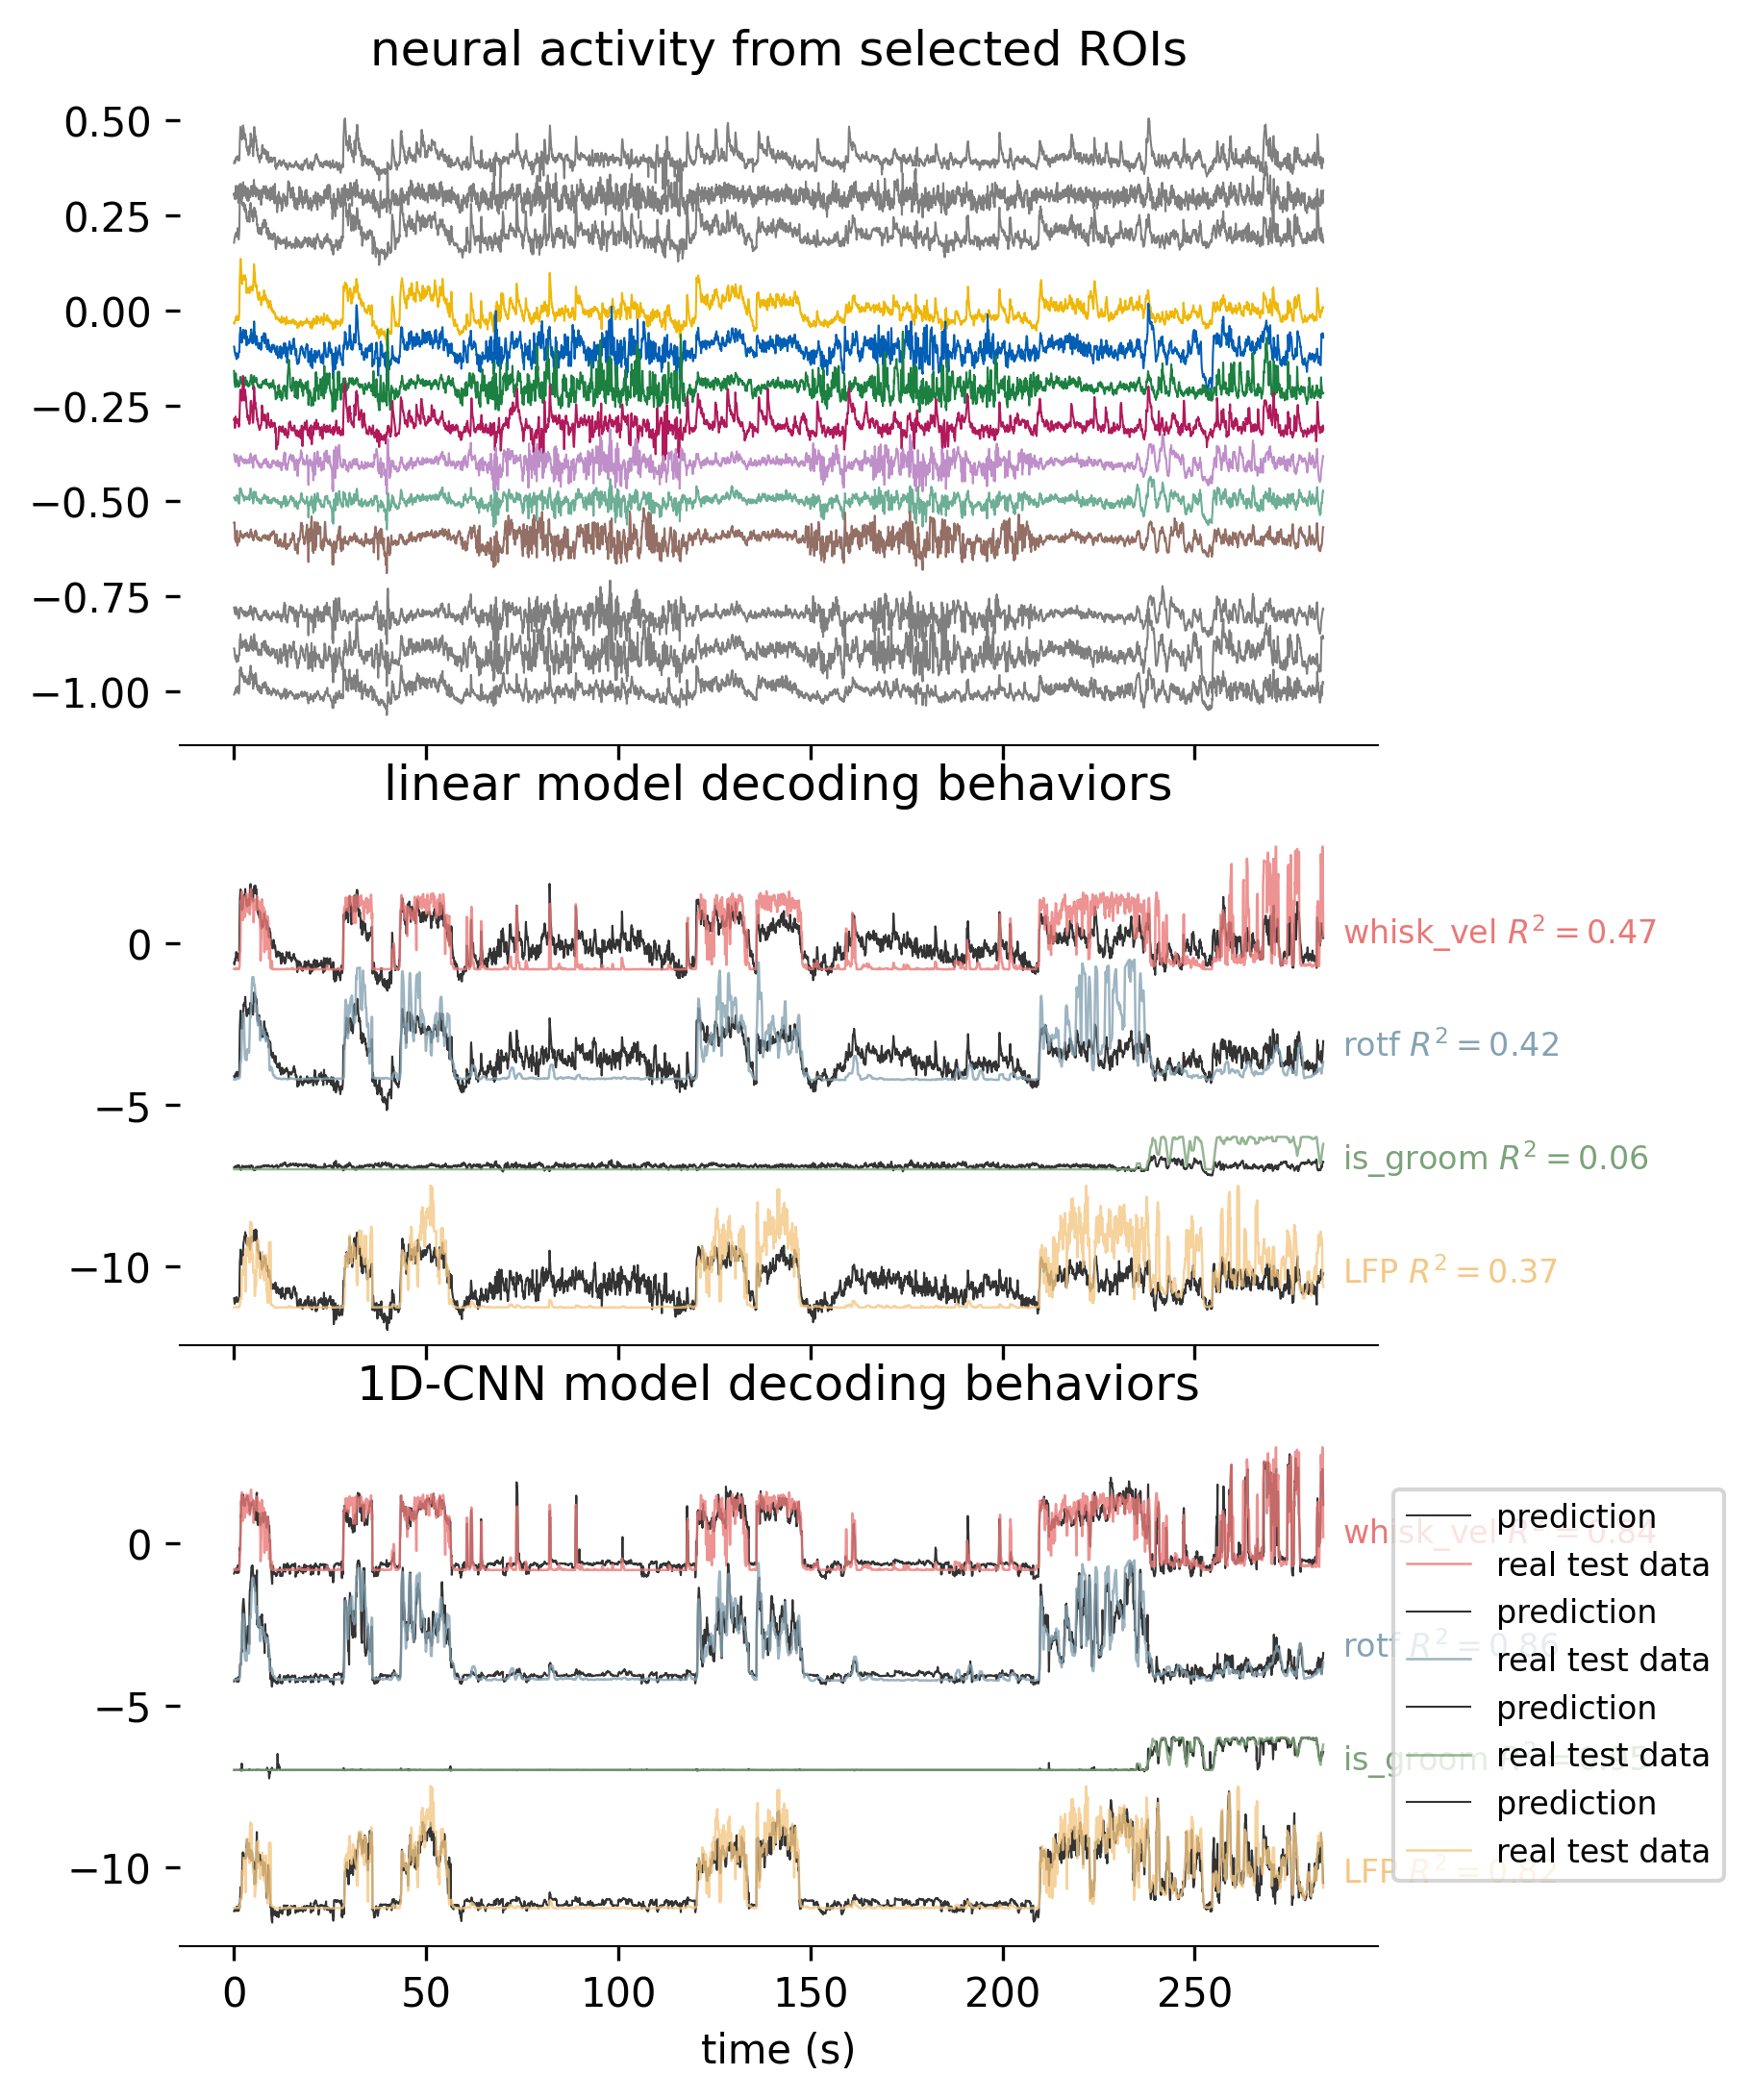

In [120]:
from matplotlib.gridspec import GridSpec
from matplotlib import colors
from skimage import measure
import matplotlib
from matplotlib import ticker
from matplotlib.ticker import FuncFormatter
fmt = lambda x, pos: '{:.0%}'.format(x)
plt.style.use('default')
gs = GridSpec(100,100)
# with plt.style.context(spstyle.get_style('nature')):
plt.rcParams['svg.fonttype'] = 'none'
fig = plt.figure(figsize=(30,30),dpi=300)


y_offset = 20;x_offset=20;x_width=5

# behavior (body and facial movements)
x_start = x_offset 
x_stop = x_start+18
y_start = y_offset 
y_stop = y_start+10
for i_ax in range(0,3):
    exec("ax{} = fig.add_subplot(gs[y_start:y_stop,x_start:x_stop])".format(i_ax))
    y_start = y_stop+1
    y_stop = y_start+8
    if i_ax < 2:
        exec("ax{}.set_xticklabels([])".format(i_ax)) 
        
#######
# plot neural activity for random ROIs
for i_count,i_number in enumerate(chosen_numbers):
    if i_count <3:
        off_set = 0.4
    else:
        off_set = -0.5
    data_2_plot = X[t_range,i_number]
    ax0.plot(t_ax,data_2_plot-0.1*i_count+off_set,linewidth=0.5,color='#7f7f7f')
    # ax0.text(t_ax[-1]-t_ax[0]+3,-0.1*i_bdp-0.02,'ROI {} ({}) '.format(i_bdp,bdp),color=palatte_dict[bdp],fontsize=8)


# plot neural activity for ROIs
for i_bdp in range(7):
    bdp = choice_body_part_dict[i_bdp]
    ind = choice_dict[i_bdp]
    data_2_plot = X[t_range,ind]
    ax0.plot(t_ax,data_2_plot-0.1*i_bdp,label=bdp,linewidth=0.5,color=palatte_dict[bdp])
    # ax0.text(t_ax[-1]-t_ax[0]+3,-0.1*i_bdp-0.02,'ROI {} ({}) '.format(i_bdp,bdp),color=palatte_dict[bdp],fontsize=8)

# plot comparison linear model
for i_beh,beh in enumerate(['whisk_vel', 'rotf', 'is_groom', 'LFP']):
    ax1.plot(t_ax,y_predict_linear_model[t_range,i_beh]-i_beh*3.5,label='prediction',linewidth=0.5,color='black',alpha=0.8)
    ax1.plot(t_ax,y[t_range,i_beh]-i_beh*3.5,label='real test data',color=palette_body[i_beh],linewidth=0.6,alpha=0.8)
    r2 = r2_score(y[t_range,i_beh],y_predict_linear_model[t_range,i_beh])
    ax1.text(t_ax[-1]-t_ax[0]+5,-i_beh*3.5,'{} $R^2=${:0.2f}'.format(beh,r2),color=palette_body[i_beh],fontsize=8)
    

# plot comparison linear model
for i_beh,beh in enumerate(['whisk_vel', 'rotf', 'is_groom', 'LFP']):
    ax2.plot(t_ax,Y_hat_concat[t_range,i_beh]-i_beh*3.5,label='prediction',linewidth=0.5,color='black',alpha=0.8)
    ax2.plot(t_ax,Y_concat[t_range,i_beh]-i_beh*3.5,label='real test data',color=palette_body[i_beh],linewidth=0.6,alpha=0.8)
    r2 = r2_score(Y_hat_concat[t_range,i_beh],Y_concat[t_range,i_beh])
    ax2.text(t_ax[-1]-t_ax[0]+5,-i_beh*3.5,'{} $R^2=${:0.2f}'.format(beh,r2),color=palette_body[i_beh],fontsize=8)
        
    
for axis in ['top','right','left','bottom']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0.5)".format(i_ax))
for axis in ['top','right','left']:
    for i_ax in range(0,3):
        exec("ax{}.spines[axis].set_linewidth(0)".format(i_ax))
        # exec("ax{}.yaxis.tick_right()".format(i_ax))
  
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5),fontsize=8)
ax1.set_ylim([-12.45464035046205, 3.718582308433501])
ax2.set_ylim([-12.45464035046205, 3.718582308433501])
ax2.set_xlabel('time (s)')
ax0.set_title('neural activity from selected ROIs')
ax1.set_title('linear model decoding behaviors')
ax2.set_title('1D-CNN model decoding behaviors')

plt.savefig('figS7-single-trial-compare.svg',format='svg',dpi=300)